<a href="https://colab.research.google.com/github/unatardedemartes-a11y/ClassFiles/blob/main/Padilla_LiviaD_EDA_predictivo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad: análisis exploratorio de datos para analítica predictiva
## Caso: suscripción a un depósito a plazo tras una llamada de telemarketing bancario

Programación para Analítica Descriptiva y Predictiva · Tema : EDA con Analítica Predictiva
Maestría en Inteligencia Artificial y Analítica de Datos · UACJ

**Nombre del estudiante:** Livia Daniela Padilla Barragan  

**Matrícula:** 275334

**Fecha:** 11-Oct-2026

## Propósito

Aplicar, de forma individual y sobre un conjunto de datos nuevo, el procedimiento de análisis exploratorio para analítica predictiva revisado en el notebook guiado del caso Telco. El producto de la actividad es una **hoja de decisiones** de preprocesamiento y modelado, sustentada en evidencia obtenida con el código.

No se entrena ningún modelo en esta actividad.

## Instrucciones de entrega

1. Completa las celdas de código y las de texto marcadas con **Tu predicción**, **Tu observación** o **Tu respuesta**.
2. Antes de entregar, ejecuta el notebook completo con *Kernel > Restart & Run All*. El notebook debe ejecutarse de principio a fin sin errores.
3. Guarda el archivo como `Apellido_Nombre_EDA_predictivo.ipynb` y entrégalo en el medio indicado por el profesor.
4. La actividad es individual. Las predicciones deben escribirse **antes** de ejecutar cada celda de código.

## Reglas de trabajo

- Usa solo el conjunto `df` y las librerías ya importadas.
- Después de la división de la parte C, el conjunto `prueba` **no se utiliza** en ninguna celda.
- Usa `random_state=42` en toda operación aleatoria, para que los resultados sean comparables.
- Las observaciones y las decisiones citan cifras obtenidas con tu propio código.

## Conjunto de datos y fuente

**Bank Marketing** (archivo `bank-additional-full.csv`), del repositorio UCI de aprendizaje automático. Cada fila es un contacto telefónico de una campaña de marketing directo de un banco portugués. El conjunto contiene 41,188 contactos ordenados por fecha, de mayo de 2008 a noviembre de 2010, y 21 columnas.


**Problema predictivo.** Clasificación binaria: dadas las características de un cliente y del contexto de la campaña, predecir si el cliente contratará el depósito a plazo (`y`).

**Diccionario de datos**

| Columna | Contenido |
| --- | --- |
| `age` | Edad del cliente |
| `job`, `marital`, `education` | Ocupación, estado civil y escolaridad |
| `default`, `housing`, `loan` | Si tiene crédito en incumplimiento, crédito hipotecario y préstamo personal |
| `contact` | Medio de contacto: `cellular` o `telephone` |
| `month`, `day_of_week` | Mes y día de la semana del último contacto de la campaña actual |
| `duration` | Duración de la última llamada, en segundos |
| `campaign` | Número de contactos con este cliente en la campaña actual, incluido el último |
| `pdays` | Días transcurridos desde el último contacto de una campaña anterior; `999` indica que no fue contactado antes |
| `previous` | Número de contactos antes de la campaña actual |
| `poutcome` | Resultado de la campaña anterior: `success`, `failure` o `nonexistent` |
| `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed` | Indicadores económicos trimestrales o mensuales: variación del empleo, índice de precios, índice de confianza del consumidor, tasa Euribor a 3 meses y número de empleados |
| `y` | Variable objetivo: `yes` si el cliente contrató el depósito, `no` si no |

## 1. Preparación del entorno y carga de datos (celda proporcionada)

Ejecuta la celda sin modificarla. Si el archivo no está en la carpeta, la celda lo descarga de una copia pública del conjunto; si ya está, lo reutiliza. El archivo usa punto y coma como separador.

In [40]:
import os
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid")
AZUL = "#1E2761"
NARANJA = "#D98E04"
COLORES_CLASE = {"no": AZUL, "yes": NARANJA}
pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 120)

url = "https://raw.githubusercontent.com/selva86/datasets/master/bank-additional-full.csv"
archivo = "bank_marketing.csv"

if not os.path.exists(archivo):
    urllib.request.urlretrieve(url, archivo)

df = pd.read_csv(archivo, sep=";")

numericas = ["age", "duration", "campaign", "pdays", "previous",
             "emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
categoricas = ["job", "marital", "education", "default", "housing", "loan",
               "contact", "month", "day_of_week", "poutcome"]
macro = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]

print("Filas y columnas:", df.shape)

Filas y columnas: (41188, 21)


## Parte A. Definición del problema

**Por qué.** Un EDA predictivo se orienta por preguntas que se responden antes de calcular nada. Una de ellas, qué información estará disponible al momento de predecir, decide qué variables pueden entrar al modelo.

Completa la columna **Respuesta** de la siguiente tabla, editando esta celda.

| Pregunta | Respuesta |
| --- | --- |
| ¿Qué es una observación? |Un cliente |
| ¿Qué se predice? |y:yes si el cliente contrato el depósito |
| ¿Qué tipo de problema es? |Clasificacion binaria |
| ¿En qué momento se haría la predicción y qué información existiría entonces? |Antes de hacer la llamada al cliente, existiria casi toda la informacion menos la duracion de la llamada y si el cliente acepta |
| ¿Qué columnas no deberían usarse como características y por qué? |duration y 'y' |

**Tu predicción.** ¿Qué porcentaje de los contactos esperas que haya terminado en contratación del depósito?

**Respuesta:** Al menos un 20%

In [41]:
#Vamos a verificarlo

#Distribución absoluta
print(df["y"].value_counts())
print()
#Distribución porcentual
print(df["y"].value_counts(normalize=True) * 100)

y
no     36548
yes     4640
Name: count, dtype: int64

y
no     88.734583
yes    11.265417
Name: proportion, dtype: float64


Fui optimista, es casi la mitad :)

## Parte B. Descripción de los datos y detección de problemas de calidad, conjunto total

**Por qué.** La descripción (tamaño, tipos, significado de las columnas) y la detección de problemas con criterios estructurales o del dominio no usan la variable objetivo ni calculan parámetros que se aplicarán al modelo. Por eso se hacen con el conjunto total `df`, antes de dividir. Esta parte **detecta y cuantifica**; las decisiones de tratamiento se toman en la hoja de la parte G.

Las verificaciones de calidad de CRISP-DM que se piden son: consistencia de valores, cantidad y distribución de valores nulos, y valores fuera de rango.

**Pista.** En este conjunto los faltantes en variables categóricas se codifican con el texto `unknown`, no con `NaN`.

**Tu predicción.** ¿Habrá valores `NaN`? ¿En qué columnas esperas encontrar `unknown` y en cuántas filas? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

**Respuesta:**
No habrá valores NaN puesto que se indica que se camiaron por unknown
Probablemente encontremos valores de unknown en las columnas relacionadas con los datos personales del cliente como: job, marital, education.

In [42]:
# B1. Estructura. Escribe el código que muestre:
#  - las dimensiones del conjunto,
#  - el tipo de dato de cada columna,
#  - el número de valores únicos por columna, de menor a mayor.

#Dimensiones del conjunto
print("Dimensiones del conjunto (filas, columnas):", df.shape)
print()

#Tipo de dato de cada columna
print("Tipos de datos por columna:")
print(df.dtypes)
print()

#Número de valores únicos por columna, de menor a mayor
print("Número de valores únicos por columna (de menor a mayor):")
print(df.nunique().sort_values(ascending=True))

Dimensiones del conjunto (filas, columnas): (41188, 21)

Tipos de datos por columna:
age                 int64
job                object
marital            object
education          object
default            object
housing            object
loan               object
contact            object
month              object
day_of_week        object
duration            int64
campaign            int64
pdays               int64
previous            int64
poutcome           object
emp.var.rate      float64
cons.price.idx    float64
cons.conf.idx     float64
euribor3m         float64
nr.employed       float64
y                  object
dtype: object

Número de valores únicos por columna (de menor a mayor):
contact              2
y                    2
default              3
loan                 3
poutcome             3
housing              3
marital              4
day_of_week          5
previous             8
education            8
emp.var.rate        10
month               10
nr.employed         1

In [43]:
# B2. Valores faltantes. Escribe el código que muestre:
#  - el total de valores NaN del conjunto,
#  - para las columnas categóricas, cuántas filas tienen "unknown" (solo las columnas con al menos una),
#  - ese conteo como porcentaje de las filas.

#Total de valores NaN del conjunto
total_nan = df.isna().sum().sum()
print("Total de valores NaN en el conjunto:", total_nan)
print()

#Columnas categóricas con "unknown" (solo las que tienen al menos una)
print("Filas con 'unknown' en columnas categóricas:")
cat_cols = df.select_dtypes(include="object").columns
unknown_counts = {
    col: (df[col] == "unknown").sum()
    for col in cat_cols
    if (df[col] == "unknown").sum() > 0
}

#Conteo y porcentaje, ordenado de mayor a menor
for col, n in sorted(unknown_counts.items(), key=lambda x: -x[1]):
    pct = n / len(df) * 100
    print(col, ":", n, "filas (", round(pct, 2), "%)")

Total de valores NaN en el conjunto: 0

Filas con 'unknown' en columnas categóricas:
default : 8597 filas ( 20.87 %)
education : 1731 filas ( 4.2 %)
housing : 990 filas ( 2.4 %)
loan : 990 filas ( 2.4 %)
job : 330 filas ( 0.8 %)
marital : 80 filas ( 0.19 %)


In [44]:
# B3. Duplicados. Escribe el código que cuente las filas completamente idénticas.

#Filas completamente idénticas
duplicados = df.duplicated().sum()
print("Filas completamente duplicadas:", duplicados)


Filas completamente duplicadas: 12


In [45]:
# B4. Consistencia entre columnas relacionadas. Escribe el código que muestre:
#  - cuántas filas tienen pdays igual a 999 y qué porcentaje es,
#  - una tabla de contingencia entre poutcome y (previous == 0),
#  - una tabla de contingencia entre poutcome y (pdays == 999).
# Pista: pd.crosstab.

#Filas con pdays == 999 y su porcentaje
n_999 = (df["pdays"] == 999).sum()
print("Filas con pdays == 999:", n_999)
print("Porcentaje:", round(n_999 / len(df) * 100, 2), "%")
print()

#Tabla de contingencia: poutcome vs (previous == 0)
print("Crosstab: poutcome vs previous == 0")
print(pd.crosstab(df["poutcome"], df["previous"] == 0))
print()

#Tabla de contingencia: poutcome vs (pdays == 999)
print("Crosstab: poutcome vs pdays == 999")
print(pd.crosstab(df["poutcome"], df["pdays"] == 999))

Filas con pdays == 999: 39673
Porcentaje: 96.32 %

Crosstab: poutcome vs previous == 0
previous     False  True 
poutcome                 
failure       4252      0
nonexistent      0  35563
success       1373      0

Crosstab: poutcome vs pdays == 999
pdays        False  True 
poutcome                 
failure        142   4110
nonexistent      0  35563
success       1373      0


In [46]:
# B5. Rangos según el dominio. Escribe el código que muestre:
#  - la edad mínima y máxima,
#  - cuántas llamadas tienen duration igual a 0,
#  - el mínimo y el máximo de campaign,
#  - cuántas filas tienen previous negativo.

#Edad mínima y máxima
print("Edad mínima:", df["age"].min())
print("Edad máxima:", df["age"].max())
print()

#Llamadas con duration == 0
n_dur0 = (df["duration"] == 0).sum()
print("Llamadas con 'duration' == 0:", n_dur0)
print()

#Mínimo y máximo de campaign
print("campaign mínimo:", df["campaign"].min())
print("campaign máximo:", df["campaign"].max())
print()

#Filas con previous negativo
n_prev_neg = (df["previous"] < 0).sum()
print("Filas con 'previous' negativo:", n_prev_neg)

Edad mínima: 17
Edad máxima: 98

Llamadas con 'duration' == 0: 4

campaign mínimo: 1
campaign máximo: 56

Filas con 'previous' negativo: 0


**Tu observación.** Resume los problemas de calidad que encontraste, con su cifra, y di cuáles dependen del significado de la variable. Escribe tu respuesta aquí y compárala con tu predicción.

**Respuesta:** En el análisis de calidad del dataset bancario encontré varios problemas:

No hay valores NaN (0 filas) pero sí faltantes codificados como 'unknown' en variables categóricas, concentrado sobre todo en 'default' (20%); también hay filas completamente duplicadas (12 filas), inconsistencias entre 'poutcome' y 'pdays' (4110 en failure ), llamadas con 'duration' = 0 (4 filas) que es imposible en una llamada real, edades en extremos (17 y 98 años) que son posibles outliers y 'campaign' con valores muy altos (hasta 56 llamadas).

**Tu respuesta.** ¿Qué harías con `unknown` en `default`: tratarla como una categoría más, imputarla o eliminar las filas? Justifica con lo observado. Escribe tu respuesta aquí.

**Respuesta:**
Tratarla como una categoría más, no imputar, no eliminar porque el porcentaje es demasiado alto como para eliminar filas y la ausencia es informativa.

## Parte C. División en entrenamiento y prueba

**Por qué.** La exploración que sigue relaciona características con la variable objetivo y fundamenta decisiones de modelado. Si usara los datos de prueba, esas decisiones incorporarían información de los datos con los que después se evaluará el modelo (fuga de información). Por eso se aparta el conjunto de prueba y no se vuelve a tocar hasta la evaluación final.

**Especificaciones.**

- 80% entrenamiento y 20% prueba.
- División estratificada según `y`.
- `random_state=42`.
- Guarda los conjuntos como `entrenamiento` y `prueba`.
- Crea `ent`, una copia de `entrenamiento`, y agrega a `ent` la columna `suscribe` con 1 si `y` es `yes` y 0 si es `no`.

**Tu predicción.** ¿La proporción de contratación será igual en entrenamiento y prueba? ¿Por qué? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

**Respuesta:** Si, porque se indico que se usara la division estratificada segun 'y'.

In [47]:
# C1. Escribe el código de la división y la creación de ent y de la columna suscribe.
# Después imprime:
#  - el tamaño de entrenamiento y de prueba,
#  - el porcentaje de contratación (y igual a yes) en cada uno.

#División estratificada 80/20 según y
entrenamiento, prueba = train_test_split( df, test_size=0.2, stratify=df["y"], random_state=42)

#Copia del conjunto de entrenamiento
ent = entrenamiento.copy()

#Columna 'suscribe' binaria (1 = yes, 0 = no)
ent["suscribe"] = (ent["y"] == "yes").astype(int)

#Tamaño de entrenamiento y de prueba
print("Tamaño entrenamiento:", entrenamiento.shape)
print("Tamaño prueba:", prueba.shape)
print()

#Porcentaje de contratación en cada conjunto
pct_ent = (entrenamiento["y"] == "yes").mean() * 100
pct_prueba = (prueba["y"] == "yes").mean() * 100
print("Porcentaje de contratación en entrenamiento:", round(pct_ent, 2), "%")
print("Porcentaje de contratación en prueba:", round(pct_prueba, 2), "%")

Tamaño entrenamiento: (32950, 21)
Tamaño prueba: (8238, 21)

Porcentaje de contratación en entrenamiento: 11.27 %
Porcentaje de contratación en prueba: 11.26 %


**Verificación (celda proporcionada).** Ejecútala para comprobar que la división coincide con las especificaciones. Si muestra que no se superó, revisa `test_size`, `stratify` y `random_state`.

In [48]:
if entrenamiento.shape[0] == 32950 and prueba.shape[0] == 8238 and "suscribe" in ent.columns and abs(ent["suscribe"].mean() - 0.1127) < 0.0005:
    print("Verificación superada.")
else:
    print("Verificación no superada: revisa la división y la columna suscribe.")

Verificación superada.


**Tu observación.** Compara las dos proporciones con tu predicción. Escribe tu respuesta aquí y compárala con tu predicción.

**Respuesta:** Era de esperarse ya que stratify=df["y"] mantiene la proporción de yes/no en ambos conjuntos.

**A partir de aquí el conjunto `prueba` no se usa.** Todo el análisis trabaja sobre `ent`.

## Parte D. Exploración del objetivo y de las variables numéricas, entrenamiento

### D1. Variable objetivo

**Por qué.** En clasificación, la distribución de la variable objetivo condiciona las métricas de evaluación, la validación y la necesidad de rebalancear. Es lo primero que se examina.

**Tu predicción.** Si un modelo respondiera siempre `no`, ¿qué exactitud obtendría? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

**Respuesta:**  En el caso de este dataset tendria una exactitud de 88.73 (lo obtuve en la parte A) lo que sera muy acertado pero incorrecto si por ejemplo la pregunta fuera si llamar o no a los clientes

Conteo por clase:
suscribe
0    29238
1     3712
Name: count, dtype: int64

Porcentaje por clase:
suscribe
0    88.73
1    11.27
Name: proportion, dtype: float64

Razón mayoritaria / minoritaria: 7.88

Exactitud de responder siempre 'no': 88.73 %



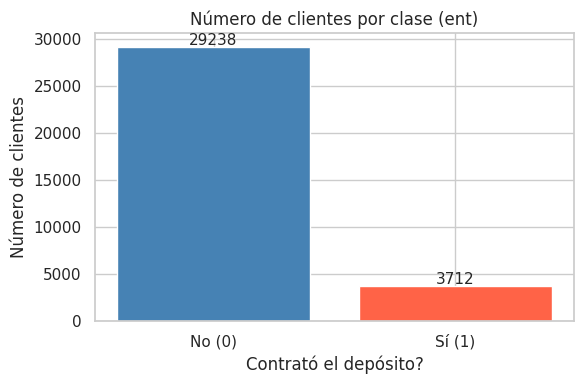

In [49]:
# D1. Escribe el código que muestre:
#  - el número y el porcentaje de clientes de cada clase en ent,
#  - la razón entre la clase mayoritaria y la minoritaria,
#  - la exactitud de responder siempre "no",
#  - una gráfica de barras con el número de clientes por clase.


#Número y porcentaje de clientes de cada clase
conteo = ent["suscribe"].value_counts().sort_index()
porcentaje = ent["suscribe"].value_counts(normalize=True).sort_index() * 100

print("Conteo por clase:")
print(conteo)
print()
print("Porcentaje por clase:")
print(porcentaje.round(2))
print()

#Razón entre clase mayoritaria y minoritaria
mayoritaria = conteo.max()
minoritaria = conteo.min()
print("Razón mayoritaria / minoritaria:", round(mayoritaria / minoritaria, 2))
print()

#Exactitud de responder siempre "no"
accuracy_trivial = (ent["suscribe"] == 0).mean() * 100
print("Exactitud de responder siempre 'no':", round(accuracy_trivial, 2), "%")
print()

#Gráfica de barras
plt.figure(figsize=(6, 4))
plt.bar(["No (0)", "Sí (1)"], conteo.values, color=["steelblue", "tomato"])
plt.title("Número de clientes por clase (ent)")
plt.ylabel("Número de clientes")
plt.xlabel("Contrató el depósito?")
for i, v in enumerate(conteo.values):
    plt.text(i, v + 200, str(v), ha="center", fontsize=11)
plt.tight_layout()
plt.show()

**Tu observación.** Compara con tu predicción de las partes A y D y explica qué implica para la evaluación del modelo. Escribe tu respuesta aquí y compárala con tu predicción.

**Respuesta:** Mi predicción en la parte A estaba equivocada, la realidad es 11.27%, casi la mitad. Esto implica que el desbalance es más severo de lo que anticipe porque desconocia el dataset.

### D2. Variables numéricas según la clase

**Por qué.** Para cada característica numérica interesa cómo se distribuye en cada clase: si lo hace de forma distinta, la variable separa a quienes contratan de quienes no. Se compara la mediana porque es resistente a valores extremos.

**Tu predicción.** ¿Cuáles de las variables numéricas esperas que más difieran entre quienes contratan y quienes no? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

**Respuesta:** La variable 'duration' ya que es poco probable que entre mas corta la llamada la respuesta a la contratacion sea que si

Variables numéricas: ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

Mediana por clase:
y                    no      yes
age               38.00    37.00
duration         164.00   448.00
campaign           2.00     2.00
pdays            999.00   999.00
previous           0.00     0.00
emp.var.rate       1.10    -1.80
cons.price.idx    93.92    93.20
cons.conf.idx    -41.80   -40.40
euribor3m          4.86     1.27
nr.employed     5195.80  5099.10



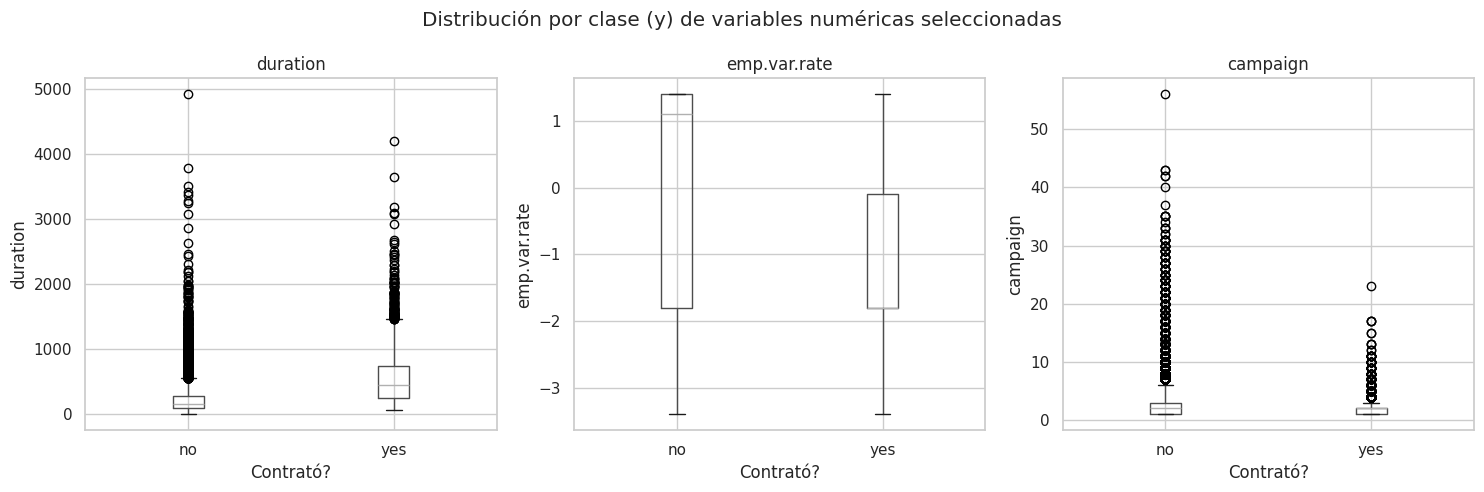

In [50]:
# D2. Escribe el código que muestre:
#  - la mediana de cada variable numérica (lista numericas) por clase de y,
#  - diagramas de caja por clase de y de al menos tres variables numéricas que elijas.


#Lista de variables numéricas excluyendo 'suscribe'
numericas = ent.select_dtypes(include=["int64", "float64"]).columns.drop("suscribe").tolist()
print("Variables numéricas:", numericas)
print()

#Mediana de cada variable numérica por clase de y
medianas = ent.groupby("y")[numericas].median().T
print("Mediana por clase:")
print(medianas.round(2))
print()

#Diagramas de caja por clase de y (al menos 3 variables)
vars_plot = ["duration", "emp.var.rate", "campaign"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, var in zip(axes, vars_plot):
    ent.boxplot(column=var, by="y", ax=ax)
    ax.set_title(var)
    ax.set_xlabel("Contrató?")
    ax.set_ylabel(var)

plt.suptitle("Distribución por clase (y) de variables numéricas seleccionadas")
plt.tight_layout()
plt.show()

**Tu observación.** Indica qué variables separan las clases y cuáles no, con las medianas. Escribe tu respuesta aquí y compárala con tu predicción.

**Respuesta:** Las variables que mejor separan a quienes contratan de quienes no son duration (las llamadas de quienes contratan duran mucho más: mediana de 448 s frente a 164 s), nr.employed y euribor3m

Las que no separan segun la mediana: previous, campaign y pdays.

### D3. Valores atípicos

**Por qué.** Los modelos lineales, las máquinas de soporte vectorial y las redes neuronales son sensibles a valores extremos y a la escala; los árboles de decisión y sus conjuntos no lo son. El EDA documenta el problema y la decisión depende del modelo.

Los límites de Tukey (1.5 veces el rango intercuartílico) se calculan con los cuartiles de los datos, por lo que se obtienen con el conjunto de entrenamiento.

**Tu predicción.** ¿Qué variables numéricas esperas que tengan más registros fuera de los límites de Tukey? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

'duration' porque tendremos desde valores donde nunca se ha marcado hasta mas de 3000 y campaign porque tenemos registros desde 1 a 56 llamadas.

In [51]:
# D3. Escribe el código que calcule, con ent, los límites inferior y superior de Tukey
# de cada variable de la lista numericas y muestre cuántos registros quedan fuera de ellos por variable.

#Cuartiles y rango intercuartílico
Q1 = ent[numericas].quantile(0.25)
Q3 = ent[numericas].quantile(0.75)
IQR = Q3 - Q1

#Límites de Tukey
lim_inf = Q1 - 1.5 * IQR
lim_sup = Q3 + 1.5 * IQR
print("Límite Inferior de Tukey:")
print(lim_inf.round(2))
print()
print("Límite superior de Tukey:")
print(lim_sup.round(2))
print()

#Registros fuera de los límites por variable
outliers = ((ent[numericas] < lim_inf) | (ent[numericas] > lim_sup)).sum()
print("Registros fuera de los límites por variable:")
print(outliers)

Límite Inferior de Tukey:
age                  9.50
duration          -221.00
campaign            -2.00
pdays              999.00
previous             0.00
emp.var.rate        -6.60
cons.price.idx      91.70
cons.conf.idx      -52.15
euribor3m           -4.08
nr.employed       4905.60
dtype: float64

Límite superior de Tukey:
age                 69.50
duration           643.00
campaign             6.00
pdays              999.00
previous             0.00
emp.var.rate         6.20
cons.price.idx      95.37
cons.conf.idx      -26.95
euribor3m           10.39
nr.employed       5421.60
dtype: float64

Registros fuera de los límites por variable:
age                368
duration          2366
campaign          1916
pdays             1226
previous          4534
emp.var.rate         0
cons.price.idx       0
cons.conf.idx      359
euribor3m            0
nr.employed          0
dtype: int64


**Tu respuesta.** ¿Eliminarías los registros atípicos de alguna variable? Justifica por variable con lo que sabes de su significado. Escribe tu respuesta aquí.

**Respuesta:** No eliminaría ninguna fila por outliers, en este dataset los valores atípicos son clientes reales con perfiles poco frecuentes pero relevantes, borrarlos sesgaría el modelo contra segmentos clave, en su lugar, trataría las variables según el modelo.

* Age: 368 outliers, las edades van de los 17 a 98 (Parte B) y son rangos de edad posibles.

* Duration: 2366 outliers. la duración de la llamada en segundos, pero los valores altos son reales, una llamada de 15 minutos puede existir.

* Campaing: 1916 outliers: numero de contactos en la campana actual, se le puede haber insistido muchas veces a un cliente.

### D4. Asimetría y re-expresión

**Por qué.** Cuando una variable tiene asimetría fuerte, una transformación monótona (raíz cuadrada o logaritmo) puede acercar su distribución a una forma simétrica. Un modelo sensible a la escala se beneficia; uno basado en árboles no. La asimetría guía la decisión.

**Tu predicción.** ¿Cuál transformación, raíz cuadrada o logaritmo (`np.log1p`), reducirá más la asimetría de `campaign`? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

**Respuesta:** Con lo que sabemos de 'campaign' (mediana 2, Q3 3, máximo 56), su asimetría positiva fuerte. Para colas así, el logaritmo (log1p) comprime los valores extremos mucho más que la raíz cuadrada, por lo que reducirá más la asimetría y acercará la distribución a una forma simétrica.

Asimetría:
          original   raiz  log1p
age          0.761  0.426  0.132
duration     3.327  1.204 -0.430
campaign     4.743  2.163  1.351



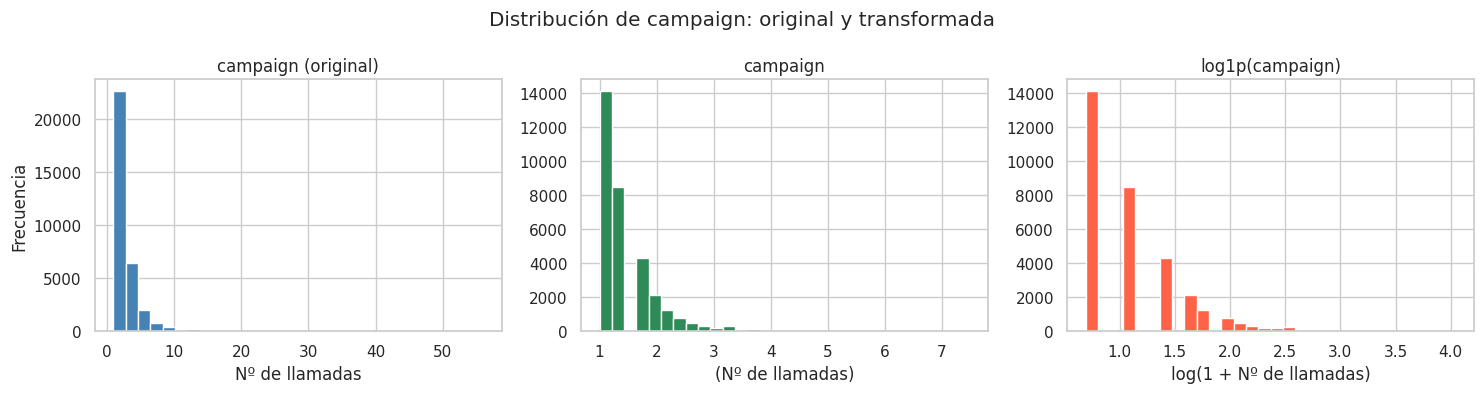

In [52]:
# D4. Escribe el código que muestre una tabla con la asimetría original, con raíz cuadrada y con
# logaritmo (np.log1p) de las variables age, duration y campaign, calculada con ent.
# Después grafica los histogramas de campaign: original y transformada.

#Tabla de asimetría: original, raíz cuadrada y log1p
vars_asim = ["age", "duration", "campaign"]

asimetrias = pd.DataFrame({
    "original": [ent[v].skew() for v in vars_asim],
    "raiz":     [np.sqrt(ent[v]).skew() for v in vars_asim],
    "log1p":    [np.log1p(ent[v]).skew() for v in vars_asim]
}, index=vars_asim)

print("Asimetría:")
print(asimetrias.round(3))
print()

#Histogramas de campaign: original y transformada
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(ent["campaign"], bins=30, color="steelblue", edgecolor="white")
axes[0].set_title("campaign (original)")
axes[0].set_xlabel("Nº de llamadas")
axes[0].set_ylabel("Frecuencia")

axes[1].hist(np.sqrt(ent["campaign"]), bins=30, color="seagreen", edgecolor="white")
axes[1].set_title("campaign")
axes[1].set_xlabel("(Nº de llamadas)")

axes[2].hist(np.log1p(ent["campaign"]), bins=30, color="tomato", edgecolor="white")
axes[2].set_title("log1p(campaign)")
axes[2].set_xlabel("log(1 + Nº de llamadas)")

plt.suptitle("Distribución de campaign: original y transformada")
plt.tight_layout()
plt.show()

**Tu observación.** Reporta las asimetrías y decide qué transformación, si alguna, aplicarías a cada variable. Escribe tu respuesta aquí y compárala con tu predicción.

**Respuesta:**
Los resultados confirman parcialmente mi predicción, log1p es la mejor transformación en las tres variables, pero con matices: en 'campaign' reduce la asimetría de 4.74 a 1.35, en duration la lleva de 3.33 a -0.43 , y en age la deja en 0.13 partiendo de 0.76 aplicaria, log1p solo para 'campaign', dejar age tal cual y duration se excluye por data leakage

## Parte E. Exploración de las variables categóricas, entrenamiento

**Por qué.** Para una característica categórica, la medida natural es la **tasa de contratación por categoría** comparada con la tasa global, junto con el número de clientes: una tasa calculada con pocos registros es poco confiable.

**Tu predicción.** ¿Qué variable categórica esperas que tenga las categorías con mayor tasa de contratación? ¿Y cuáles esperas que casi no separen las clases? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

**Respuesta:** Probablemente 'job' y espero que no tengan tanto peso las de default, housing, loan.

In [53]:
# E1. Escribe el código que muestre:
#  - el número de categorías de cada variable de la lista categoricas,
#  - la tasa global de contratación en ent.

#Lista de variables categóricas
categoricas = ent.select_dtypes(include="object").columns.drop("y").tolist()
print("Variables categóricas:", categoricas)
print()

#Número de categorías de cada variable categórica
print("Número de categorías por variable:")
print(ent[categoricas].nunique().sort_values(ascending=False))
print()

#Tasa global de contratación en ent
tasa_global = ent["suscribe"].mean()
print("Tasa global de contratación:", round(tasa_global * 100, 2), "%")

Variables categóricas: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']

Número de categorías por variable:
job            12
month          10
education       8
day_of_week     5
marital         4
default         3
loan            3
housing         3
poutcome        3
contact         2
dtype: int64

Tasa global de contratación: 11.27 %


In [54]:
# E2. Escribe el código que construya una tabla con el número de clientes y la tasa de contratación (en %)
# de cada categoría de cada variable de categoricas. Muestra:
#  - las 12 categorías con mayor tasa,
#  - las 8 con menor tasa,
#  - las tablas de default, housing, loan y day_of_week.
# Pista: reutiliza el patrón melt + groupby + agg del notebook guiado del caso Telco.

#Construir el DataFrame largo (melt + groupby + agg)
largo = (ent[categoricas]
         .astype(str)
         .assign(suscribe=ent["suscribe"])
         .melt(id_vars="suscribe", var_name="caracteristica", value_name="categoria"))

tasas = (largo
         .groupby(["caracteristica", "categoria"])["suscribe"]
         .agg(clientes="count", tasa="mean"))
tasas["tasa"] = (tasas["tasa"] * 100).round(1)

#Las 12 categorías con mayor tasa de contratación
print("Categorías con MAYOR tasa de contratación:")
print(tasas.sort_values("tasa", ascending=False).head(12))
print()

#Las 8 categorías con menor tasa
print("Categorías con MENOR tasa de contratación:")
print(tasas.sort_values("tasa", ascending=False).tail(8))
print()

#Tablas de default, housing, loan y day_of_week
for col in ["default", "housing", "loan", "day_of_week"]:
    print(f"Tasa de contratación según {col}:")
    print(tasas.loc[col])
    print()

Categorías con MAYOR tasa de contratación:
                           clientes  tasa
caracteristica categoria                 
poutcome       success         1105  64.9
month          dec              143  50.3
               mar              436  49.8
               sep              464  44.6
               oct              587  43.3
job            student          711  30.5
               retired         1366  25.5
month          apr             2085  20.5
education      illiterate        16  18.8
marital        unknown           65  16.9
education      unknown         1397  14.8
contact        cellular       20908  14.7

Categorías con MENOR tasa de contratación:
                            clientes  tasa
caracteristica categoria                  
education      basic.6y         1865   8.4
job            services         3196   7.9
education      basic.9y         4826   7.6
job            blue-collar      7441   6.9
month          may             11011   6.3
contact        telephone

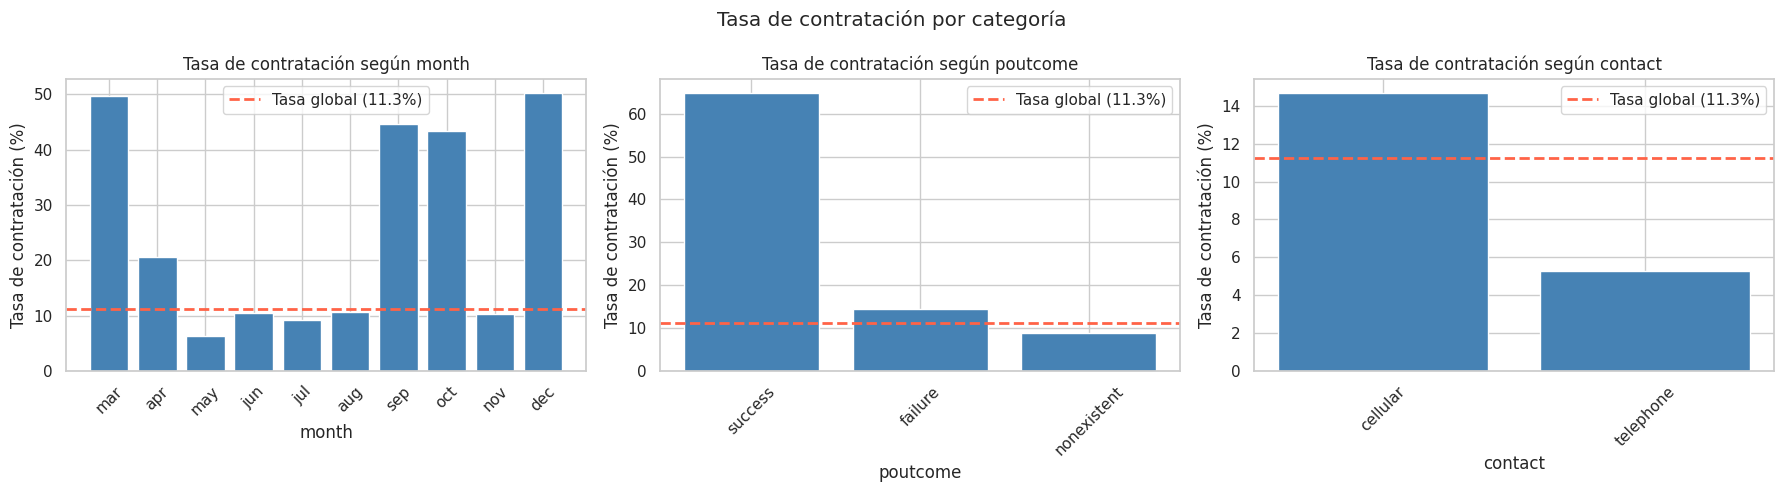

In [55]:
# E3. Escribe el código que grafique la tasa de contratación por categoría de month (en orden
# cronológico: mar, apr, may, jun, jul, aug, sep, oct, nov, dec), poutcome y contact,
# con una línea horizontal en la tasa global.

#Tasa global de referencia
tasa_global = ent["suscribe"].mean() * 100

#Orden cronológico de month
orden_meses = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]

#Variables a graficar
graficos = [
    ("month", orden_meses),
    ("poutcome", None),   # orden natural (por tasa, se ordenará en el gráfico)
    ("contact", None)
]

#Crear figura con 3 subgráficos
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (var, orden) in zip(axes, graficos):
    # Extraer tasas de esa variable
    tabla = tasas.loc[var].copy()

    # Reordenar si hace falta
    if orden is not None:
        # Filtrar solo las categorías presentes en el orden definido
        tabla = tabla.loc[[c for c in orden if c in tabla.index]]
    else:
        tabla = tabla.sort_values("tasa", ascending=False)

    # Gráfico de barras
    ax.bar(tabla.index, tabla["tasa"], color="steelblue", edgecolor="white")
    ax.axhline(tasa_global, color="tomato", linestyle="--", linewidth=2,
               label=f"Tasa global ({tasa_global:.1f}%)")
    ax.set_title(f"Tasa de contratación según {var}")
    ax.set_xlabel(var)
    ax.set_ylabel("Tasa de contratación (%)")
    ax.legend()
    ax.tick_params(axis="x", rotation=45)

plt.suptitle("Tasa de contratación por categoría")
plt.tight_layout()
plt.show()

**Tu observación.** Identifica las categorías con mayor y menor tasa, con su tasa y su número de clientes, y las variables que casi no separan las clases. Escribe tu respuesta aquí y compárala con tu predicción.

**Respuesta:** Predije: que job tendría las tasas más altas y que default, housing y loan casi no separarían. Fallé en la primera, acerté en la segunda

**Tu respuesta.** En `default`, ¿qué indica que la categoría `unknown` tenga una tasa de contratación distinta a la de `no`? ¿Qué hay que cuidar con las categorías `yes` de `default` o `illiterate` de `education`? Escribe tu respuesta aquí.

**Respuesta:** Que default = unknown tenga tasa distinta a no (5.2% vs 12.9%) indica que "no saber si tiene mora" no es lo mismo que "saber que no tiene mora": probablemente son clientes nuevos o sin historial crediticio, y eso ya de por sí es información, por eso conviene dejarla como categoría propia en vez de imputarla

## Parte F. Relaciones entre características y variable `duration`, entrenamiento

### F1. Relaciones entre características

**Por qué.** Dos características muy relacionadas son redundantes y pueden causar inestabilidad en modelos lineales (colinealidad).

**Tu predicción.** ¿Qué pares de indicadores económicos (lista `macro`) esperas que estén más correlacionados? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

**Respuesta:** Espero que euribor3m, emp.var.rate y nr.employed estén correlacionados entre sí, porque los tres se mueven con el ciclo económico

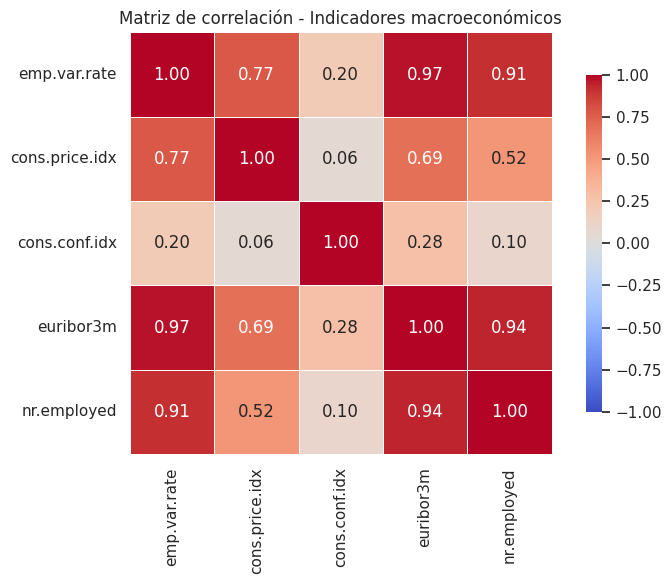

In [56]:
# F1. Escribe el código que muestre un mapa de calor con la matriz de correlación de las variables de la lista macro,
# calculada con ent, con los valores anotados en cada celda.

#Lista de indicadores macroeconómicos
macro = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]

#Matriz de correlación calculada
corr_macro = ent[macro].corr()

#Mapa de calor con valores anotados
plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_macro,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1, vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)
plt.title("Matriz de correlación - Indicadores macroeconómicos")
plt.tight_layout()
plt.show()

**Tu observación.** Reporta los pares más correlacionados y la decisión que implican. Escribe tu respuesta aquí y compárala con tu predicción.

**Respuesta:** Los pares más correlacionados son:

euribor3m & emp.var.rate: 0.97

euribor3m & nr.employed: 0.95

emp.var.rate & nr.employed: 0.91

### F2. La variable `duration`

**Por qué.** Una variable puede tener una relación muy fuerte con el objetivo y aun así no ser utilizable. Esto ocurre cuando su valor solo se conoce después del evento que se quiere predecir.

In [57]:
# F2. Escribe el código que muestre el resumen estadístico (describe) de duration por clase de y.

print("Resumen de duration por clase de y:")
print(ent.groupby("y")["duration"].describe().round(2))

Resumen de duration por clase de y:
       count    mean     std   min    25%    50%    75%     max
y                                                              
no   29238.0  221.15  208.30   0.0   95.0  164.0  279.0  4918.0
yes   3712.0  549.40  397.49  63.0  252.0  448.0  737.0  4199.0


**Tu respuesta.** ¿Incluirías `duration` como característica de un modelo que se usará para decidir a quién llamar? Justifica con la definición de la variable y con lo observado. Escribe tu respuesta aquí.

**Tu respuesta.** El conjunto está ordenado por fecha y los indicadores económicos varían con el tiempo. ¿Qué implica dividir al azar, como en la parte C, para un modelo que se usará en campañas futuras? Escribe tu respuesta aquí.

## Parte G. Hoja de decisiones y justificación del uso de los datos

### G1. Hoja de decisiones

**Por qué.** El producto de un EDA predictivo es una lista de decisiones, cada una con su evidencia. Ninguna decisión se aplica todavía sobre los datos.

Completa la tabla con **al menos siete decisiones**, cada una con un hallazgo de tu análisis (con su cifra), la decisión y el tema del curso donde se aplicaría (preprocesamiento, modelos, evaluación). Debe aparecer al menos una decisión sobre cada uno de estos aspectos: variable no utilizable, valores faltantes o códigos especiales, desbalance de clases, redundancia entre características y asimetría.

Edita esta celda y agrega las filas que necesites.



| Hallazgo (con cifra) | Decisión | Se aplica en |
| --- | --- | --- |
|duration tiene medianas muy distintas por clase (448 s vs 164 s), pero solo se conoce después de la llamada |Excluir duration del modelo |Preprocesamiento |
|'unknown' aparece en 8 categóricas, destacando default (20.9%) y education (4.2%) |Dejar 'unknown' como categoría propia (no imputar, no eliminar): la ausencia es informativa |Preprocesamiento |
|Desbalance severo: 88.7% "no" vs 11.3% "sí"; un modelo trivial ya saca 88.7% de accuracy |No usar accuracy como métrica |Evaluación / Modelos|
|euribor3m, emp.var.rate y nr.employed correlacionados >0.91 entre sí |Quedarse con uno solo de los tres (ej. euribor3m) o eliminarlos todos si el modelo prefiere aprender del cliente |Preprocesamiento |
|campaign con asimetría 4.74 - baja a 1.35 con log1p; age de 0.76 - 0.13; duration de 3.33 - -0.43 |log1p a campaign  y no transformar age |Preprocesamiento |
|pdays = 999 en el 96.3% de las filas, y 4,110 filas con poutcome="failure" y pdays=999 (inconsistencia) |Binarizar pdays |Preprocesamiento |
|poutcome = "success" con tasa 64.9% pero solo 1,105 clientes (soporte bajo) |Mantener poutcome |Modelos / Evaluación |

### G2. Uso de los datos

**Tu respuesta.** En esta actividad, ¿qué partes se hicieron con el conjunto total y cuáles solo con entrenamiento? Explica el criterio. Escribe tu respuesta aquí.

**Respuesta:** con el conjunto total solo la Parte B: estructura, unknown, duplicados, consistencia pdays/poutcome, rangos, outliers, asimetría. Se puede usar df porque son verificaciones y porque no altera la evaluacion.  

Con el conjunto de entrenamiento las partes C en adelante donde se calculan estadísticos y decisiones que condicionan el modelo

**Tu respuesta.** Si hubieras explorado también el conjunto de prueba, ¿qué decisión de tu hoja podría quedar sesgada y cómo se reflejaría en la evaluación final? Escribe tu respuesta aquí.